In [84]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
import numpy as np

In [85]:
df = pd.read_csv("C:\\power_forecast\\data\\pjme_hourly.csv")
df.head()

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


## Phase 1 : Exploration et modélisation 

### Exploration et nettoyage des données


In [86]:
df.describe()

,PJME_MW
count,145366.000000
mean,32080.222831
std,6464.012166
min,14544.000000
25%,27573.000000
50%,31421.000000
75%,35650.000000
max,62009.000000


In [87]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  145366 non-null  str    
 1   PJME_MW   145366 non-null  float64
dtypes: float64(1), str(1)
memory usage: 4.9 MB


In [88]:
df["Datetime"] = pd.to_datetime(df["Datetime"])

In [89]:
df["Datetime"].dtype

dtype('<M8[us]')

In [90]:
df.duplicated().sum()

np.int64(0)

In [91]:
df.isna().sum()

Datetime    0
PJME_MW     0
dtype: int64

In [92]:
num_cols = df.select_dtypes(include="number").columns

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)

IQR = Q3 - Q1

outliers = (df[num_cols] < (Q1 - 1.5 * IQR)) | (df[num_cols] > (Q3 + 1.5 * IQR))

df[outliers.any(axis=1)]
outliers.sum()

PJME_MW    3455
dtype: int64

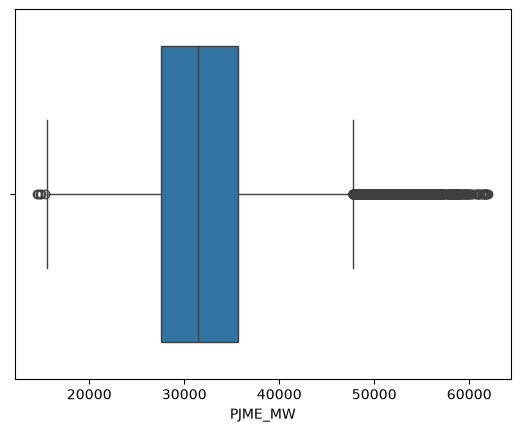

In [93]:
for col in num_cols:
    sns.boxplot(x=df[col])
    

In [94]:
df = df.sort_values(by="Datetime",ascending=True)

In [95]:
df[["Datetime"]].head(10)

,Datetime
8734,2002-01-01 01:00:00
8735,2002-01-01 02:00:00
8736,2002-01-01 03:00:00
8737,2002-01-01 04:00:00
8738,2002-01-01 05:00:00
8739,2002-01-01 06:00:00
8740,2002-01-01 07:00:00
8741,2002-01-01 08:00:00
8742,2002-01-01 09:00:00
8743,2002-01-01 10:00:00


In [96]:
df = df.sort_values(by="Datetime").reset_index(drop=True)

In [97]:
df[["Datetime"]].head(10)



,Datetime
0,2002-01-01 01:00:00
1,2002-01-01 02:00:00
2,2002-01-01 03:00:00
3,2002-01-01 04:00:00
4,2002-01-01 05:00:00
5,2002-01-01 06:00:00
6,2002-01-01 07:00:00
7,2002-01-01 08:00:00
8,2002-01-01 09:00:00
9,2002-01-01 10:00:00


### EDA, Feature Engineering et Modélisation

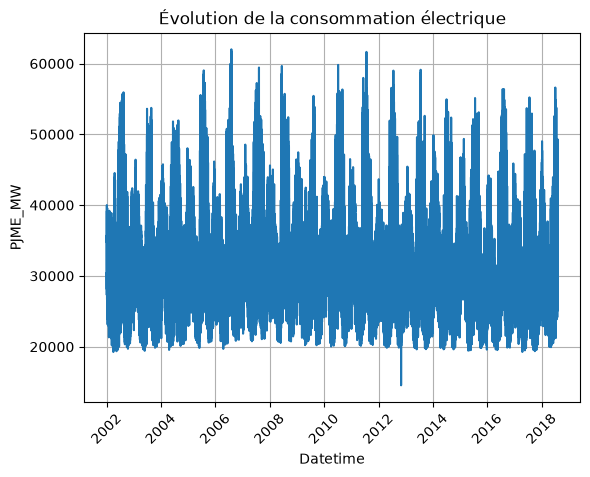

In [98]:
sns.lineplot(data=df, x="Datetime", y="PJME_MW")
plt.xticks(rotation=45)
plt.title("Évolution de la consommation électrique")
plt.grid()
plt.show()


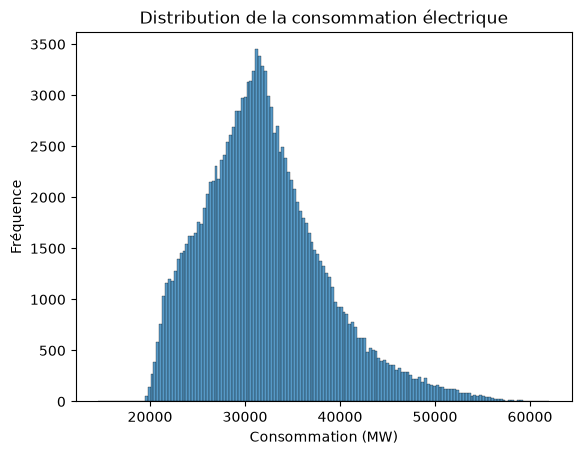

In [99]:
sns.histplot(data=df, x="PJME_MW")
plt.title("Distribution de la consommation électrique")
plt.xlabel("Consommation (MW)")
plt.ylabel("Fréquence")
plt.show()

In [100]:
df["Hour"] = df["Datetime"].dt.hour

hourly = df.groupby("Hour")["PJME_MW"].mean()
print(hourly)

Hour
0     29523.611194
1     27535.589964
2     26344.055207
3     25679.097666
4     25414.924728
5     25749.431000
6     27162.853912
7     29611.046880
8     31490.827831
9     32628.888247
10    33497.403433
11    34197.643117
12    34588.618356
13    34759.571146
14    34916.601684
15    34940.669693
16    35065.392209
17    35596.051502
18    36421.931496
19    36426.629911
20    36106.840211
21    35741.057280
22    34453.149884
23    32047.501486
Name: PJME_MW, dtype: float64


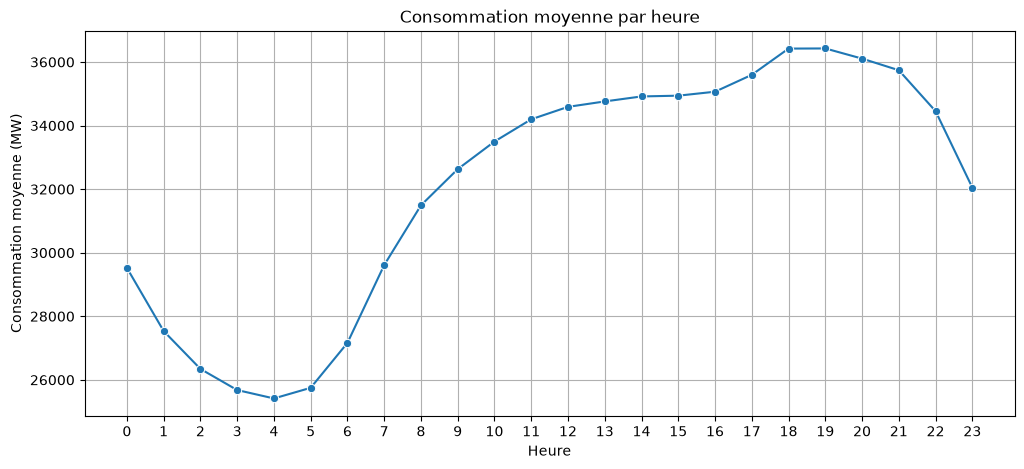

In [101]:
plt.figure(figsize=(12, 5))

sns.lineplot(x=hourly.index, y=hourly.values, marker="o")

plt.title("Consommation moyenne par heure")
plt.xlabel("Heure")
plt.ylabel("Consommation moyenne (MW)")
plt.xticks(range(24))
plt.grid()
plt.show()

In [102]:
df["DayOfWeek"] = df["Datetime"].dt.dayofweek

In [103]:
daily = df.groupby("DayOfWeek")["PJME_MW"].mean()

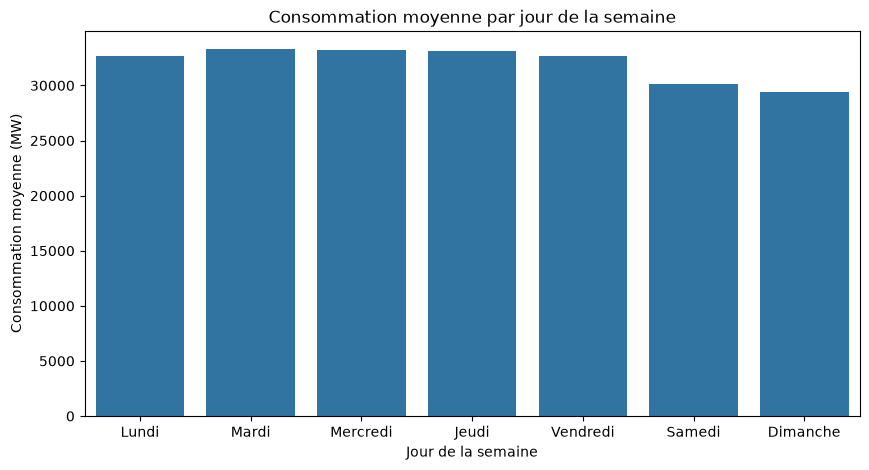

In [105]:
plt.figure(figsize=(10, 5))

sns.barplot(x=daily.index, y=daily.values)

plt.title("Consommation moyenne par jour de la semaine")
plt.xlabel("Jour de la semaine")
plt.ylabel("Consommation moyenne (MW)")
plt.xticks(
    ticks=range(7),
    labels=["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
)

plt.show()

In [106]:
df["Month"] = df["Datetime"].dt.month
monthly = df.groupby("Month")["PJME_MW"].mean()

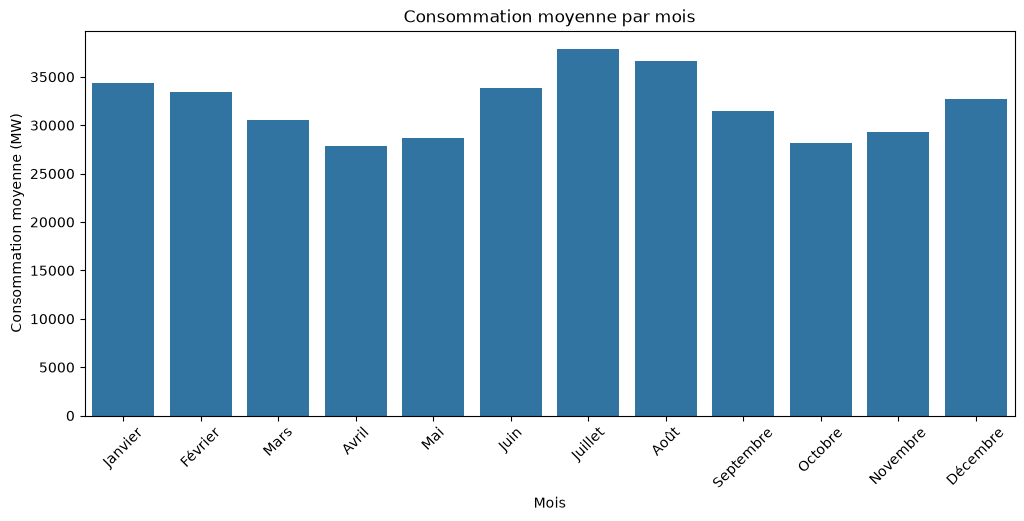

In [107]:
plt.figure(figsize=(12, 5))

sns.barplot(x=monthly.index, y=monthly.values)

plt.title("Consommation moyenne par mois")
plt.xlabel("Mois")
plt.ylabel("Consommation moyenne (MW)")

plt.xticks(
    ticks=range(12),
    labels=["Janvier", "Février", "Mars", "Avril", "Mai", "Juin",
            "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"],
    rotation=45
)

plt.show()

In [108]:
df["Rolling_Mean"] = (
    df["PJME_MW"]
    .shift(1)
    .rolling(window=24)
    .mean()
)

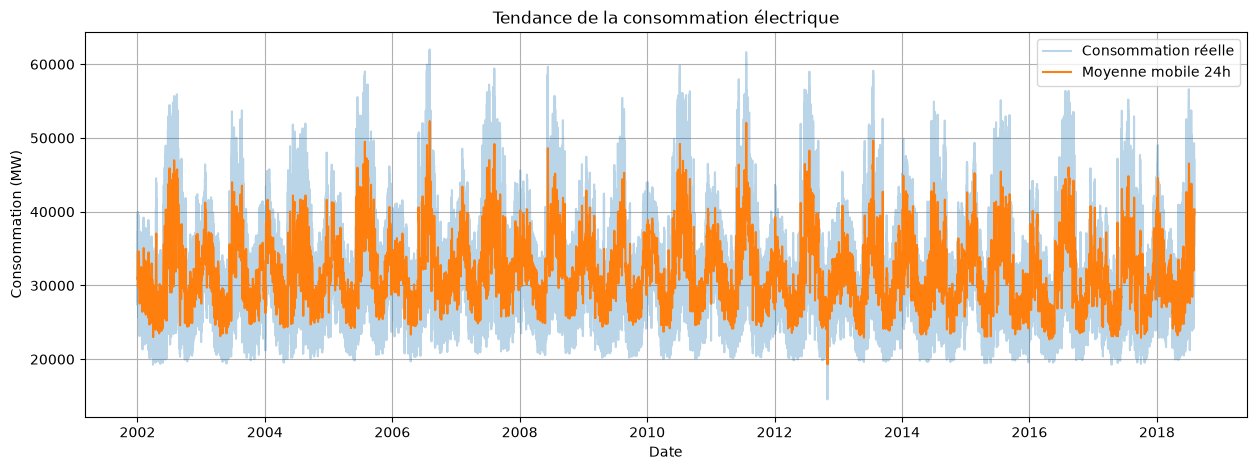

In [109]:
plt.figure(figsize=(15, 5))

plt.plot(df["Datetime"], df["PJME_MW"], alpha=0.3, label="Consommation réelle")
plt.plot(df["Datetime"], df["Rolling_Mean"], label="Moyenne mobile 24h")

plt.title("Tendance de la consommation électrique")
plt.xlabel("Date")
plt.ylabel("Consommation (MW)")
plt.legend()
plt.grid()
plt.show()

In [110]:
df["Year"] = df["Datetime"].dt.year
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

In [111]:
df.head(24)

,Datetime,PJME_MW,Hour,DayOfWeek,Month,Rolling_Mean,Year,IsWeekend
0,2002-01-01 01:00:00,30393.0,1,1,1,NaN,2002,0
1,2002-01-01 02:00:00,29265.0,2,1,1,NaN,2002,0
2,2002-01-01 03:00:00,28357.0,3,1,1,NaN,2002,0
3,2002-01-01 04:00:00,27899.0,4,1,1,NaN,2002,0
4,2002-01-01 05:00:00,28057.0,5,1,1,NaN,2002,0
5,2002-01-01 06:00:00,28654.0,6,1,1,NaN,2002,0
6,2002-01-01 07:00:00,29308.0,7,1,1,NaN,2002,0
7,2002-01-01 08:00:00,29595.0,8,1,1,NaN,2002,0
8,2002-01-01 09:00:00,29943.0,9,1,1,NaN,2002,0
9,2002-01-01 10:00:00,30692.0,10,1,1,NaN,2002,0


In [112]:
df["lag_24"] = df["PJME_MW"].shift(24)

In [113]:
df[["PJME_MW", "Rolling_Mean"]].head(30)

,PJME_MW,Rolling_Mean
0,30393.0,NaN
1,29265.0,NaN
2,28357.0,NaN
3,27899.0,NaN
4,28057.0,NaN
5,28654.0,NaN
6,29308.0,NaN
7,29595.0,NaN
8,29943.0,NaN
9,30692.0,NaN


In [114]:
df["lag_168"] = df["PJME_MW"].shift(168)

In [115]:
df["roll_24"] = df["PJME_MW"].shift(1).rolling(window=24).mean()

In [116]:
df[["Datetime", "PJME_MW", "lag_24", "lag_168", "roll_24"]].iloc[165:172]

,Datetime,PJME_MW,lag_24,lag_168,roll_24
165,2002-01-07 22:00:00,35997.0,32731.0,NaN,33075.541667
166,2002-01-07 23:00:00,33579.0,30646.0,NaN,33211.625000
167,2002-01-08 00:00:00,31187.0,28337.0,NaN,33333.833333
168,2002-01-08 01:00:00,29445.0,26862.0,30393.0,33452.583333
169,2002-01-08 02:00:00,28670.0,25976.0,29265.0,33560.208333
170,2002-01-08 03:00:00,28375.0,25641.0,28357.0,33672.458333
171,2002-01-08 04:00:00,28542.0,25666.0,27899.0,33786.375000


In [117]:
df["Datetime"].diff().value_counts().head(10)

Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
0 days 00:00:00         4
Name: count, dtype: int64

In [118]:
df["Datetime"].duplicated().sum()

np.int64(4)

In [119]:
df[df["Datetime"].duplicated(keep=False)].sort_values("Datetime")

,Datetime,PJME_MW,Hour,DayOfWeek,Month,Rolling_Mean,Year,IsWeekend,lag_24,lag_168,roll_24
112487,2014-11-02 02:00:00,23755.0,2,6,11,26700.625000,2014,1,22606.0,20728.0,26700.625000
112488,2014-11-02 02:00:00,22935.0,2,6,11,26748.500000,2014,1,22015.0,20382.0,26748.500000
121223,2015-11-01 02:00:00,21171.0,2,6,11,25358.250000,2015,1,22841.0,21015.0,25358.250000
121224,2015-11-01 02:00:00,21567.0,2,6,11,25288.666667,2015,1,22429.0,20498.0,25288.666667
130127,2016-11-06 02:00:00,20795.0,2,6,11,24856.833333,2016,1,22403.0,20774.0,24856.833333
130128,2016-11-06 02:00:00,21692.0,2,6,11,24789.833333,2016,1,21997.0,20232.0,24789.833333
138863,2017-11-05 02:00:00,21236.0,2,6,11,24344.375000,2017,1,21281.0,20772.0,24344.375000
138864,2017-11-05 02:00:00,20666.0,2,6,11,24342.500000,2017,1,20792.0,20317.0,24342.500000


In [120]:
df[df["Datetime"].diff() > pd.Timedelta(hours=1)][
    ["Datetime", "PJME_MW"]
]

,Datetime,PJME_MW
2306,2002-04-07 04:00:00,24487.0
7176,2002-10-27 03:00:00,20605.0
11040,2003-04-06 04:00:00,22902.0
15910,2003-10-26 03:00:00,20641.0
19774,2004-04-04 04:00:00,23208.0
24812,2004-10-31 03:00:00,20585.0
28508,2005-04-03 04:00:00,23414.0
33546,2005-10-30 03:00:00,23302.0
37242,2006-04-02 04:00:00,20833.0
42280,2006-10-29 03:00:00,23310.0


In [121]:
df.isna().sum()

Datetime          0
PJME_MW           0
Hour              0
DayOfWeek         0
Month             0
Rolling_Mean     24
Year              0
IsWeekend         0
lag_24           24
lag_168         168
roll_24          24
dtype: int64

In [122]:
df = df.dropna().reset_index(drop=True)

In [123]:
df.isnull().sum()

Datetime        0
PJME_MW         0
Hour            0
DayOfWeek       0
Month           0
Rolling_Mean    0
Year            0
IsWeekend       0
lag_24          0
lag_168         0
roll_24         0
dtype: int64

### Préparation des données

In [124]:
X = df[[
    "Hour",
    "DayOfWeek",
    "Month",
    "Year",
    "IsWeekend",
    "lag_24",
    "lag_168",
    "roll_24"
]]

y = df["PJME_MW"]

In [125]:
cat_cols = ["Hour", "DayOfWeek", "Month", "IsWeekend"]

num_cols = ["Year", "lag_24", "lag_168", "roll_24"]

In [126]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols)
    ]
)

In [127]:
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [128]:
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (116158, 8)
X_test  : (29040, 8)
y_train : (116158,)
y_test  : (29040,)


### Entraînement et évaluation du modèle

In [129]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [130]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [131]:
y_baseline = X_test["lag_24"]

In [132]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Linear Regression": y_pred,
    "Baseline lag_24": y_baseline
})

comparison.head(10)

,Actual,Linear Regression,Baseline lag_24
116158,23728.0,23127.168956,26208.0
116159,22743.0,21994.046844,25240.0
116160,22276.0,21355.711829,24753.0
116161,22029.0,21117.478567,24694.0
116162,22248.0,21422.843908,25232.0
116163,23000.0,22803.241421,27062.0
116164,24053.0,25257.978822,30258.0
116165,25079.0,26785.820042,31865.0
116166,25947.0,27626.098564,32447.0
116167,26327.0,28069.301011,32455.0


In [133]:
def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100
    }

In [134]:
results = pd.DataFrame({
    "Linear Regression": evaluate_model(y_test, y_pred),
    "Baseline lag_24": evaluate_model(y_test, y_baseline)
})
results

,Linear Regression,Baseline lag_24
MAE,1675.605746,2184.243492
RMSE,2240.054906,3009.111395
R2,0.880938,0.785151
MAPE (%),5.294630,6.931605
